# My model (numerical, shape only) vs Denis' pipeline (analytic, my mask midline) on the `synch_fix_newest` EOD tables

Both silent-fish controls; every EOD of the newest tables, each at its own video frame (no offset); masks `*_Shiv_tracking_final.pkl`.

- **Mine** (`eod_assignment_control_groups.py`): 2D resistive grid, BEM conductivities, sources on the mask midline with the sink at the
  tail tip, other fish as bodies; recorded peak pattern and model pattern (× −1) each scaled to max |v| = 1 over the 10 pairs;
  L2 distance; nearest fish wins. Raw model and recorded voltages and both normalising factors are saved per EOD.
- **Denis** (`EODAssignment/analysis/social_electric_fish_runners/denis_synch_fix_runner.py --table synch_fix_newest`): his analytic field model and cosine similarity, with my mask
  midline for every fish.
- **Groups**: all EODs; **clean good** = the EOD's newest frame passes the mask QC, Denis' SLEAP-good rule and the 0.8 × median
  mask-length limit (`clean_good_frames_newest.py --fresh`).

An EOD where some fish has no mask midline counts as wrong for both pipelines. Both pipelines are scored on the same EODs.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import binomtest

OUT = 'results/newest_qc'
REC = {
    '2-fish': dict(res='results/eod_ground_truth', emitter=1, true='A', label='2-fish (2024-02-13)', fish=(0, 1)),
    '3-fish': dict(res='results/eod_ground_truth_3fish', emitter=0, true='C', label='3-fish (2024-10-15)', fish=(0, 1, 2)),
}
PIPE_COL = {'mine (numerical, shape only)': '#1F5FBF', "Denis (analytic, my mask midline)": '#E8710A'}

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z**2 / (2 * n)) / (1 + z**2 / n); hw = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (c - hw), 100 * (c + hw)

E = {}
for name, c in REC.items():
    mine = pd.read_csv(f"{c['res']}/conductivities/my_model_shape_synch_fix_newest.csv")
    den = pd.read_csv(f"{c['res']}/conductivities/denis_mask_midline_offset/denis_mask_midline_all_eods_synch_fix_newest.csv")
    clean = pd.read_csv(f"{c['res']}/eod_clean_good_synch_fix_newest.csv")
    assert len(mine) == len(den) == len(clean)
    assert (mine.Frame.to_numpy() == den.Frame.to_numpy()).all() and (mine.Frame.to_numpy() == clean.Frame.to_numpy()).all()
    e = pd.DataFrame({'eod_row': mine.eod_row, 'Frame': mine.Frame, 'clean_good': clean.clean_good,
                      'mine (numerical, shape only)': (mine.pick == c['emitter']).to_numpy(),
                      "Denis (analytic, my mask midline)": (den.pick == c['true']).to_numpy(),
                      'pick_mine': mine.pick, 'pick_denis': den.pick})
    E[name] = e
    nomid = (~mine[[f'fish_ok_{f}' for f in c['fish']]].all(axis=1)).sum()
    print(f"{c['label']}: {len(e)} EODs, clean good {e.clean_good.sum()}; EODs where some fish has no mask midline: mine {nomid}, "
          f"Denis {den.pick.isna().sum()}")

2-fish (2024-02-13): 18801 EODs, clean good 3536; EODs where some fish has no mask midline: mine 160, Denis 160
3-fish (2024-10-15): 19796 EODs, clean good 6764; EODs where some fish has no mask midline: mine 48, Denis 48


## % correct

In [2]:
rows = []
for name, c in REC.items():
    e = E[name]
    for grp, m in (('all EODs', np.ones(len(e), bool)), ('clean good (newest QC)', e.clean_good.to_numpy())):
        for p in PIPE_COL:
            k, n = int(e.loc[m, p].sum()), int(m.sum()); lo, hi = wilson(k, n)
            rows.append(dict(recording=c['label'], EODs=grp, pipeline=p, n=n, wrong=n - k, pct_correct=100 * k / n, ci_lo=lo, ci_hi=hi))
        a_, b_ = e.loc[m, 'mine (numerical, shape only)'].to_numpy(), e.loc[m, "Denis (analytic, my mask midline)"].to_numpy()
        up, dn = (a_ & ~b_).sum(), (~a_ & b_).sum()
        print(f"{c['label']}, {grp}: both right {(a_ & b_).sum()}, only mine {up}, only Denis {dn}, both wrong {(~a_ & ~b_).sum()}; "
              f"McNemar p = {binomtest(up, up + dn).pvalue if up + dn else 1:.1e}")
ACC = pd.DataFrame(rows); print(); print(ACC.to_string(index=False, float_format=lambda v: f'{v:.2f}'))
ACC.to_csv(f'{OUT}/accuracy_mine_vs_denis_synch_fix_newest.csv', index=False)
pd.concat({k: v for k, v in E.items()}, names=['recording', 'i']).to_csv(f'{OUT}/picks_mine_vs_denis_synch_fix_newest.csv')

2-fish (2024-02-13), all EODs: both right 17990, only mine 230, only Denis 199, both wrong 382; McNemar p = 1.5e-01
2-fish (2024-02-13), clean good (newest QC): both right 3502, only mine 4, only Denis 14, both wrong 16; McNemar p = 3.1e-02
3-fish (2024-10-15), all EODs: both right 17590, only mine 182, only Denis 267, both wrong 1757; McNemar p = 7.0e-05


3-fish (2024-10-15), clean good (newest QC): both right 6628, only mine 7, only Denis 54, both wrong 75; McNemar p = 4.3e-10

          recording                   EODs                          pipeline     n  wrong  pct_correct  ci_lo  ci_hi
2-fish (2024-02-13)               all EODs      mine (numerical, shape only) 18801    581        96.91  96.65  97.15
2-fish (2024-02-13)               all EODs Denis (analytic, my mask midline) 18801    612        96.74  96.48  96.99
2-fish (2024-02-13) clean good (newest QC)      mine (numerical, shape only)  3536     30        99.15  98.79  99.41
2-fish (2024-02-13) clean good (newest QC) Denis (analytic, my mask midline)  3536     20        99.43  99.13  99.63
3-fish (2024-10-15)               all EODs      mine (numerical, shape only) 19796   2024        89.78  89.35  90.19
3-fish (2024-10-15)               all EODs Denis (analytic, my mask midline) 19796   1939        90.21  89.78  90.61
3-fish (2024-10-15) clean good (newest QC)      mine (n

## Figure

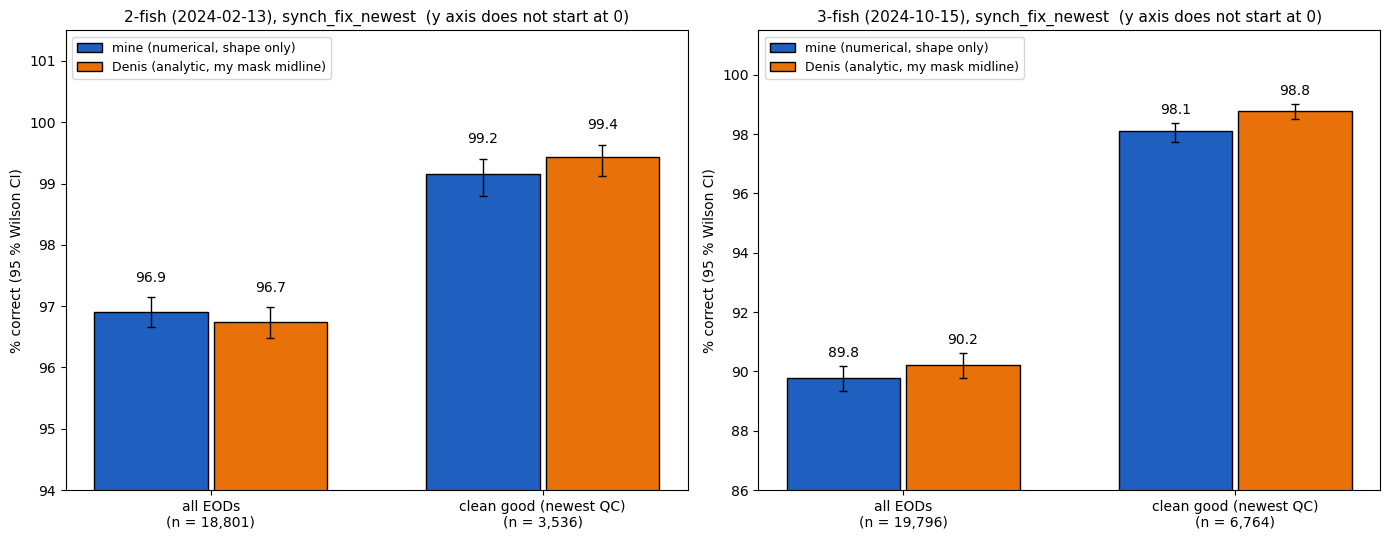

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5))
for A, (name, c) in zip(axs, REC.items()):
    t = ACC[ACC.recording == c['label']]; grps = ['all EODs', 'clean good (newest QC)']; w = 0.36
    for g, grp in enumerate(grps):
        for i, p in enumerate(PIPE_COL):
            s = t[(t.EODs == grp) & (t.pipeline == p)].iloc[0]; xx = g + (i - 0.5) * w
            A.bar(xx, s.pct_correct, w * 0.95, color=PIPE_COL[p], edgecolor='k', label=p if g == 0 else None)
            A.errorbar(xx, s.pct_correct, [[s.pct_correct - s.ci_lo], [s.ci_hi - s.pct_correct]], color='k', capsize=3, lw=1)
            A.text(xx, s.ci_hi + 0.2, f'{s.pct_correct:.1f}', ha='center', va='bottom', fontsize=10)
    A.set_xticks(range(len(grps)), [f"{g_}\n(n = {t[t.EODs == g_].n.iloc[0]:,})" for g_ in grps])
    A.set_ylim(np.floor(t.ci_lo.min() / 2) * 2 - 2, 101.5); A.set_ylabel('% correct (95 % Wilson CI)')
    A.set_title(f"{c['label']}, synch_fix_newest  (y axis does not start at 0)", fontsize=11); A.legend(loc='upper left', fontsize=9)
fig.tight_layout(); fig.savefig(f'{OUT}/accuracy_mine_vs_denis_synch_fix_newest.png', dpi=100, bbox_inches='tight'); plt.show()